# AutoGluon API Overview

- This notebook explores `autogluon.tabular` on a synthetic customer-churn table
  whose label depends on known features, so every output can be checked against
  the truth
- The pedagogical arc:
  - Load a table and let AutoGluon infer the problem and the feature types
  - Train a zoo of models with one `fit()` call and read the leaderboard
  - Predict, evaluate, and explain the predictor
  - Control the training: model families, bagging, stacking, and presets
  - Reuse the same API for regression and multiclass problems
  - Save, reload, and slim down a predictor for deployment

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import autogluon.tabular as agt
import autogluon.tabular.configs.presets_configs as agpresets
import pandas as pd

In [2]:
import helpers.hnotebook as hnotebook

import AutoGluon_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)
# Hide the GPU probe warnings (no `torch` in the image) and the SHAP internals.
utils.silence_noisy_loggers()

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

print("autogluon.tabular version: ", agt.__version__)

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpods96vx8.json --HistoryManager.hist_file=:memory:


autogluon.tabular version:  1.6.3


## Library Overview

- **What problem it solves**: training a strong model on a table takes many
  steps
  - Encode categorical, datetime, and text columns
  - Pick and tune several model families
  - Validate without leaking the test set
  - Ensemble the best models
  - AutoGluon runs all of them from one call, in a time budget you set
- **Key abstraction**: a `TabularPredictor` owns one label and one directory
  - `fit()` fills the directory with a set of trained models and an ensemble
  - Every other method reads from it
- **Mental model**:

| Object | Description | Comments |
|--------|-------------|----------|
| `TabularDataset(data)` | A `pandas.DataFrame` subclass | Also loads a CSV or Parquet file from a path or URL |
| `TabularPredictor(label, eval_metric, path)` | Container of the trained models | Infers `problem_type` from the label column |
| `.fit(train_data, presets, time_limit)` | Trains many models, then a weighted ensemble | `presets` trades accuracy against time, size, and latency |
| `.leaderboard(data)` | One row per trained model | Scores, fit time, and prediction time |
| `.predict(data)` / `.predict_proba(data)` | Predictions of the best model | The best model is often the ensemble |
| `.evaluate(data)` | Dictionary of metrics | Every score is "higher is better" |
| `.feature_importance(data)` | Permutation importance per feature | Drop of the score when a column is shuffled |

- **Key classes**:
  - `TabularPredictor`: fits, stores, and serves the models
  - `TabularDataset`: reads tables, behaves like a `DataFrame`

# Part 1: Data

## Cell 1.1: Generate a Table With a Known Answer

- The generator returns one row per customer with mixed column types
  - Numbers, strings, a date, missing values, and a constant column
- `churned` depends only on `contract`, `support_calls`, `tenure_months`, and
  `monthly_charges`
  - `region`, `signup_date`, and `country` are noise by construction
- Two more columns can act as labels later:
  - `lifetime_value` for regression
  - `contract` for multiclass classification

In [3]:
# Generate 2,000 synthetic customers.
customers_df = utils.make_synthetic_customers(2000)
print("customers_df.shape=", customers_df.shape)
display(customers_df.head())

customers_df.shape= (2000, 9)


,tenure_months,monthly_charges,contract,support_calls,region,signup_date,country,churned,lifetime_value
0,23,91.13,one-year,2,west,2023-09-24,US,yes,1650.47
1,61,54.90,month-to-month,2,east,2020-11-14,US,no,3816.10
2,3,NaN,two-year,1,east,2023-12-08,US,no,62.70
3,33,34.66,one-year,1,south,2021-02-08,US,no,1128.80
4,58,98.43,month-to-month,3,south,2021-05-24,US,yes,5459.34


In [4]:
# Count the missing values per column.
display(customers_df.isna().sum().to_frame("n_missing"))
# Outcome: only `monthly_charges` has missing values, about 5% of the rows.

,n_missing
tenure_months,0
monthly_charges,102
contract,0
support_calls,0
region,0
signup_date,0
country,0
churned,0
lifetime_value,0


## Cell 1.2: Split Train and Test

- The split is stratified on `churned`, so both sets have the same churn rate
- `lifetime_value` is removed from the classification data
  - It would be a feature here, and a label only in Part 5

In [5]:
# Split the data, keeping the churn rate equal in the two sets.
train_df, test_df = utils.split_train_test(customers_df, stratify_col="churned")
churn_train_df = train_df.drop(columns=["lifetime_value"])
churn_test_df = test_df.drop(columns=["lifetime_value"])
print("churn_train_df.shape=", churn_train_df.shape)
print("churn_test_df.shape=", churn_test_df.shape)
print(
    "churn rate (train)=", round((churn_train_df["churned"] == "yes").mean(), 3)
)

churn_train_df.shape= (1600, 8)
churn_test_df.shape= (400, 8)
churn rate (train)= 0.364


## Cell 1.3: `TabularDataset` Is a `DataFrame`

- `TabularDataset` adds file loading to `pandas.DataFrame` and nothing else
  - E.g., `agt.TabularDataset("https://.../train.csv")` downloads and parses a file
- Every `TabularPredictor` method also accepts a plain `DataFrame`

In [6]:
# Wrap the training data and check its type.
train_data = agt.TabularDataset(churn_train_df)
print("type(train_data)=", type(train_data))
print(
    "isinstance(train_data, pd.DataFrame)=",
    isinstance(train_data, pd.DataFrame),
)

type(train_data)= <class 'pandas.core.frame.DataFrame'>
isinstance(train_data, pd.DataFrame)= True


# Part 2: Train a Predictor

## Cell 2.1: Fit With One Call

- `TabularPredictor` needs only the label
  - `eval_metric` defaults to `accuracy` for classification
  - ROC-AUC is used here since it scores the ranking of the probabilities and
    ignores the 0.5 threshold
  - `path` is the directory where the models are saved
- `fit()` arguments used here:
  - `presets="medium_quality"`: fast training, no bagging (see Part 4)
  - `time_limit`: upper bound in seconds for the whole fit
  - `excluded_model_types`: skips the neural networks, which need `torch`, not
    installed in this image
- The log prints each decision: problem type, feature processing, models
  trained, and the validation score of each one

In [7]:
# Train the default model zoo on the churn data.
predictor = agt.TabularPredictor(
    label="churned",
    eval_metric="roc_auc",
    path="tmp.autogluon/api_churn",
)
_ = predictor.fit(
    train_data,
    presets="medium_quality",
    time_limit=60,
    excluded_model_types=["NN_TORCH", "FASTAI"],
)

Verbosity: 2 (Standard Logging)


=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.13
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Thu Oct 29 23:24:01 UTC 2026
CPU Count:          8
Pytorch Version:    Can't import torch
CUDA Version:       Can't get cuda version from torch
Memory Avail:       28.27 GB / 30.65 GB (92.2%)
Disk Space Avail:   81.89 GB / 86.80 GB (94.3%)


Presets specified: ['medium_quality']


Using hyperparameters preset: hyperparameters='default'


Beginning AutoGluon training ... Time limit = 60s


AutoGluon will save models to "/git_root/tutorials/AutoGluon/tmp.autogluon/api_churn"


... (102 outputs left out)

	0.04s	 = Training   runtime


	0.0s	 = Validation runtime


AutoGluon training complete, total runtime = 5.25s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 3366.4 rows/s (320 batch size)


TabularPredictor saved. To load, use: predictor = TabularPredictor.load("/git_root/tutorials/AutoGluon/tmp.autogluon/api_churn")


## Cell 2.2: Read What AutoGluon Inferred

- The label has two values, so the problem is `binary`
- The positive class is the second value in sorted order (`yes`)
  - Pass `positive_class=...` to `TabularPredictor` to choose it
- `fit()` held out part of the training data to validate the models, since the
  preset does not bag

In [8]:
# Print the problem definition inferred from the label column.
print("predictor.problem_type=", predictor.problem_type)
print("predictor.eval_metric=", predictor.eval_metric.name)
print("predictor.class_labels=", predictor.class_labels)
print("predictor.positive_class=", predictor.positive_class)

predictor.problem_type= binary
predictor.eval_metric= roc_auc
predictor.class_labels= ['no', 'yes']
predictor.positive_class= yes


## Cell 2.3: Inspect the Feature Types

- AutoGluon assigns a type to each column, then a feature generator per type
  - Strings with few values become `category`
  - The date becomes an integer and 4 calendar columns
- Compare the input columns and the features the models use
  - `country` has a single value, so it is dropped

In [9]:
# Show the type and the special tags of each feature.
print(predictor.feature_metadata)

('category', [])             : 2 | ['contract', 'region']
('float', [])                : 1 | ['monthly_charges']
('int', [])                  : 2 | ['tenure_months', 'support_calls']
('int', ['datetime_as_int']) : 5 | ['signup_date', 'signup_date.year', 'signup_date.month', 'signup_date.day', 'signup_date.dayofweek']


In [10]:
# Compare the original columns with the features the models use.
print("predictor.original_features=", predictor.original_features)
print("predictor.features()=", predictor.features())

predictor.original_features= ['tenure_months', 'monthly_charges', 'contract', 'support_calls', 'region', 'signup_date', 'country']
predictor.features()= ['tenure_months', 'monthly_charges', 'contract', 'support_calls', 'region', 'signup_date']


In [11]:
# Apply the same feature processing to new rows.
display(predictor.transform_features(churn_test_df.head(3)))
# Outcome: `signup_date` is expanded in year, month, day, and day of week.

,tenure_months,monthly_charges,support_calls,contract,region,signup_date,signup_date.year,signup_date.month,signup_date.day,signup_date.dayofweek
0,65,71.47,2,0,3,1644105600000000000,2022,2,6,6
1,33,62.81,0,0,1,1667433600000000000,2022,11,3,3
2,16,86.12,4,2,0,1660003200000000000,2022,8,9,1


# Part 3: Predict and Evaluate

## Cell 3.1: Predict Labels and Probabilities

- `predict()` returns a label per row
  - For a binary problem the label is "positive" when the probability is at
    least `predictor.decision_threshold`, 0.5 by default
- `predict_proba()` returns one column per class
- The test rows still contain `churned`: AutoGluon ignores the label column at
  prediction time

In [12]:
# Predict the label of 5 test customers.
display(predictor.predict(churn_test_df.head()).to_frame())

,churned
0,no
1,no
2,no
3,no
4,yes


In [13]:
# Predict the probability of each class for the same customers.
display(predictor.predict_proba(churn_test_df.head()))

,no,yes
0,0.827185,0.172815
1,0.703272,0.296728
2,0.517335,0.482665
3,0.960685,0.039315
4,0.277443,0.722557


## Cell 3.2: Evaluate on the Test Set

- `evaluate()` returns the eval metric and other metrics for the problem type
- The binary metrics except ROC-AUC depend on the 0.5 threshold
  - `AutoGluon.example.ipynb` shows how to move the threshold

In [14]:
# Compute the test metrics of the best model.
test_scores = predictor.evaluate(churn_test_df)
display(pd.Series(test_scores, name="score").to_frame())

,score
roc_auc,0.796489
accuracy,0.735000
balanced_accuracy,0.698145
mcc,0.412516
f1,0.607407
precision,0.661290
recall,0.561644


# Part 4: Inspect and Control the Models

## Cell 4.1: Read the Leaderboard

- One row per model
  - `score_val`: score on the internal validation data, used to rank the models
    and build the ensemble
  - `score_test`: score on the data passed to `leaderboard()`
  - `fit_time` and `pred_time_test`: the cost of each model, in seconds
- `WeightedEnsemble_L2` averages the predictions of the other models with
  weights learned on the validation data

In [15]:
# Score every model on the test set.
leaderboard_df = predictor.leaderboard(churn_test_df)
cols = ["model", "score_test", "score_val", "fit_time", "pred_time_test"]
display(leaderboard_df[cols])

,model,score_test,score_val,fit_time,pred_time_test
0,WeightedEnsemble_L2,0.796489,0.845969,1.590939,0.124136
1,XGBoost,0.795977,0.816810,0.178875,0.010404
2,LightGBMXT,0.795815,0.840306,0.307374,0.006895
3,CatBoost,0.795464,0.844067,0.648932,0.005096
4,ExtraTreesGini,0.793846,0.826847,0.601150,0.101469
5,ExtraTreesEntr,0.791473,0.830734,0.591082,0.110100
6,RandomForestEntr,0.783316,0.820952,0.587925,0.100894
7,LightGBM,0.782359,0.821459,0.270966,0.002862
8,RandomForestGini,0.775860,0.817550,0.596470,0.100383
9,LightGBMLarge,0.754584,0.814190,0.654698,0.004074


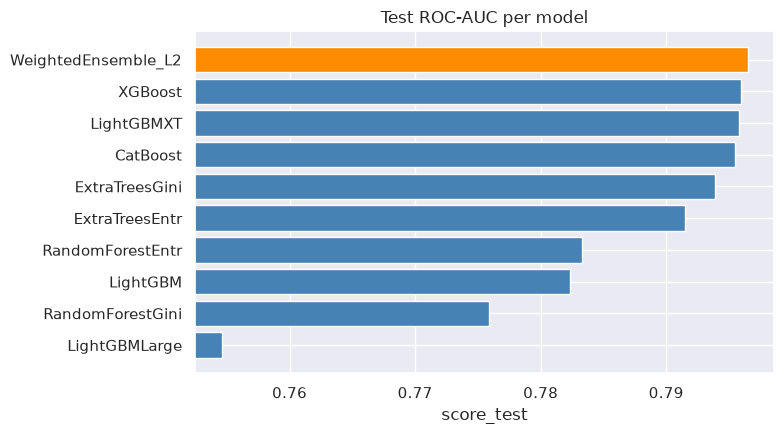

In [16]:
# Plot the test score of each model.
utils.plot_leaderboard(leaderboard_df, title="Test ROC-AUC per model")
# Outcome: most models are within a few points of each other, since the
# generator is a simple logistic model.

## Cell 4.2: Explain the Predictor With Feature Importance

- `feature_importance()` shuffles one column at a time and measures the drop of
  the eval metric
  - It explains the whole predictor, ensemble included
  - `num_shuffle_sets` repeats the shuffle to estimate the noise (`stddev`,
    `p_value`)
- The generator gives the right answer: `region` and `signup_date` are noise

In [17]:
# Compute the permutation importance of each feature on the test set.
importance_df = predictor.feature_importance(churn_test_df, num_shuffle_sets=3)
display(importance_df)

These features in provided data are not utilized by the predictor and will be ignored: ['country']


Computing feature importance via permutation shuffling for 6 features using 400 rows with 3 shuffle sets...


	2.62s	= Expected runtime (0.87s per shuffle set)


	0.54s	= Actual runtime (Completed 3 of 3 shuffle sets)


,importance,stddev,p_value,n,p99_high,p99_low
contract,0.134029,0.019934,0.003646,3,0.248254,0.019804
support_calls,0.074345,0.017847,0.009337,3,0.176612,-0.027922
tenure_months,0.049159,0.027034,0.043872,3,0.204066,-0.105749
monthly_charges,0.008728,0.004609,0.040864,3,0.035139,-0.017683
region,0.001088,0.002570,0.269895,3,0.015812,-0.013637
signup_date,0.000378,0.000468,0.148532,3,0.003058,-0.002303


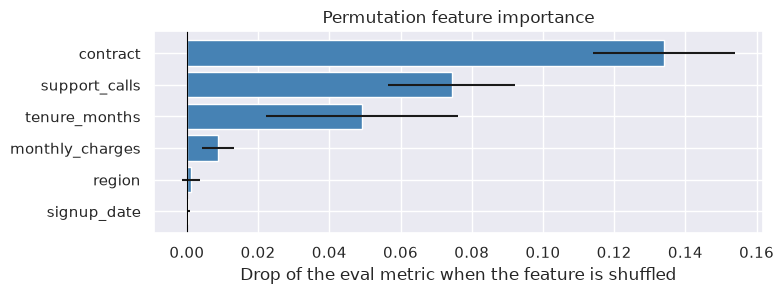

In [18]:
# Plot the importances with one standard deviation.
utils.plot_feature_importance(importance_df)
# Outcome: `contract`, `support_calls`, and `tenure_months` lead, while `region`
# and `signup_date` are close to 0.

## Cell 4.3: Choose the Models, Then Bag and Stack Them

- `hyperparameters` maps a model family to its settings
  - `{}` means the default settings
  - E.g., `GBM` is LightGBM, `CAT` is CatBoost, `XT` is Extra Trees
- `num_bag_folds=5` trains each model on 5 folds (bagging)
  - Every row gets an out-of-fold prediction, so no data is held out
- `num_stack_levels=1` adds a second layer of models that also read the
  out-of-fold predictions of the first layer (stacking)
- The model names show the structure
  - `_BAG_L1` is a bagged first-layer model
  - `_BAG_L2` is a bagged second-layer model
- The image does not install `ray`, so the folds are trained one after the
  other, as the log says

- `verbosity=1` hides the training log from now on

In [19]:
# Train three model families with 5-fold bagging and one stack level.
bagged_predictor = agt.TabularPredictor(
    label="churned",
    eval_metric="roc_auc",
    path="tmp.autogluon/api_churn_bagged",
    verbosity=1,
)
_ = bagged_predictor.fit(
    train_data,
    hyperparameters={"GBM": {}, "CAT": {}, "XT": {}},
    num_bag_folds=5,
    num_stack_levels=1,
    time_limit=120,
)

AutoGluon infers your prediction problem is: 'binary' (because only two unique label-values observed).


	If 'binary' is not the correct problem_type, please manually specify the problem_type parameter during Predictor init (You may specify problem_type as one of: ['binary', 'multiclass', 'regression', 'quantile'])


Will use sequential fold fitting strategy because import of ray failed. Reason: ray is required to train folds in parallel for TabularPredictor or HPO for MultiModalPredictor. A quick tip is to install via `pip install "ray>=2.43.0,<2.59.0"`


In [20]:
# Show the layers of the bagged and stacked predictor.
bagged_leaderboard_df = bagged_predictor.leaderboard(churn_test_df)
cols = ["model", "score_test", "score_val", "stack_level", "fit_time"]
display(bagged_leaderboard_df[cols])
# Outcome: the second layer does not beat `CatBoost_BAG_L1`, so the ensembles
# put all their weight on it. Stacking helps on larger and harder tables, not on
# a simple logistic generator.

,model,score_test,score_val,stack_level,fit_time
0,CatBoost_BAG_L1,0.796894,0.841145,1,3.692161
1,WeightedEnsemble_L2,0.796894,0.841145,2,3.726929
2,WeightedEnsemble_L3,0.796894,0.841145,3,3.757991
3,ExtraTrees_BAG_L1,0.794480,0.820646,1,0.601019
4,CatBoost_BAG_L2,0.794467,0.830599,2,9.397066
5,LightGBM_BAG_L1,0.790664,0.820809,1,1.527865
6,ExtraTrees_BAG_L2,0.789613,0.824500,2,6.402003
7,LightGBM_BAG_L2,0.781294,0.813232,2,7.451304


In [21]:
# Print the weight of each model in the second-layer ensemble.
ensemble_info = bagged_predictor.info()["model_info"]["WeightedEnsemble_L2"]
print("weights=", ensemble_info["children_info"]["S1F1"]["model_weights"])

weights= {'CatBoost_BAG_L1': np.float64(1.0)}


## Cell 4.4: Presets Bundle These Choices

- A preset is a dictionary of `fit()` arguments
  - `medium_quality`: no bagging, the default
  - `good_quality` and `high_quality`: bagging, stacking, then a refit of the
    best models on all the data (`refit_full`) for fast inference
  - `best_quality`: keeps all the bagged models for the highest accuracy and the
    largest model
- Arguments passed to `fit()` override the preset, e.g., `time_limit`

In [22]:
# Show the `fit()` arguments set by each common preset.
presets = ["medium_quality", "good_quality", "high_quality", "best_quality"]
presets_dict = agpresets.tabular_presets_dict
presets_df = pd.DataFrame(
    {name: pd.Series(presets_dict[name]) for name in presets}
).T
display(presets_df)

,auto_stack,dynamic_stacking,hyperparameters,refit_full,save_bag_folds,set_best_to_refit_full,time_limit
medium_quality,False,NaN,NaN,NaN,NaN,NaN,NaN
good_quality,True,auto,light,True,False,True,3600
high_quality,True,auto,zeroshot,True,False,True,3600
best_quality,True,auto,zeroshot,NaN,NaN,NaN,3600


# Part 5: Other Problem Types

## Cell 5.1: Regression

- The same code with a float label trains regressors
  - The default eval metric becomes the root mean squared error (RMSE)
- AutoGluon reports error metrics with a minus sign, so that a higher score is
  always better
  - An RMSE of 350 shows up as `-350`

In [23]:
# Predict the customer lifetime value from the other columns.
value_train_df = train_df.drop(columns=["churned"])
value_test_df = test_df.drop(columns=["churned"])
regressor = agt.TabularPredictor(
    label="lifetime_value",
    path="tmp.autogluon/api_value",
    verbosity=1,
)
_ = regressor.fit(
    value_train_df, hyperparameters={"GBM": {}, "LR": {}}, time_limit=30
)
print("regressor.problem_type=", regressor.problem_type)
print("regressor.eval_metric=", regressor.eval_metric.name)

AutoGluon infers your prediction problem is: 'regression' (because dtype of label-column == float and many unique label-values observed).


	If 'regression' is not the correct problem_type, please manually specify the problem_type parameter during Predictor init (You may specify problem_type as one of: ['binary', 'multiclass', 'regression', 'quantile'])


regressor.problem_type= regression
regressor.eval_metric= root_mean_squared_error


In [24]:
# Evaluate the regressor on the test set.
display(pd.Series(regressor.evaluate(value_test_df), name="score").to_frame())
# Outcome: R2 is close to 1, since the value is tenure times charges plus 10%
# noise.

,score
root_mean_squared_error,-349.329739
mean_squared_error,-122031.266657
mean_absolute_error,-242.003493
r2,0.954927
pearsonr,0.977679
median_absolute_error,-149.728032


## Cell 5.2: Multiclass Classification

- A string label with more than two values gives a `multiclass` problem
- `predict_proba()` returns one column per class

In [25]:
# Predict the contract type of each customer.
contract_predictor = agt.TabularPredictor(
    label="contract",
    path="tmp.autogluon/api_contract",
    verbosity=1,
)
_ = contract_predictor.fit(
    churn_train_df, hyperparameters={"GBM": {}}, time_limit=30
)
print("contract_predictor.problem_type=", contract_predictor.problem_type)
print("contract_predictor.class_labels=", contract_predictor.class_labels)
display(contract_predictor.predict_proba(churn_test_df.head(3)))

AutoGluon infers your prediction problem is: 'multiclass' (because dtype of label-column == object).


	If 'multiclass' is not the correct problem_type, please manually specify the problem_type parameter during Predictor init (You may specify problem_type as one of: ['binary', 'multiclass', 'regression', 'quantile'])


contract_predictor.problem_type= multiclass
contract_predictor.class_labels= ['month-to-month', 'one-year', 'two-year']


,month-to-month,one-year,two-year
0,0.518415,0.319118,0.162467
1,0.538583,0.210139,0.251278
2,0.417372,0.268787,0.313841


# Part 6: Save, Load, and Deploy

## Cell 6.1: Reload a Predictor From Its Directory

- `fit()` saves everything in `predictor.path` as it goes
- `TabularPredictor.load(path)` restores the predictor in a new process
  - The AutoGluon and Python versions must match the ones used to train

In [26]:
# Reload the first predictor and check that it gives the same predictions.
reloaded = agt.TabularPredictor.load(predictor.path)
are_equal = reloaded.predict(churn_test_df).equals(
    predictor.predict(churn_test_df)
)
print("predictor.path=", predictor.path)
print("are_equal=", are_equal)

predictor.path= /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn
are_equal= True


## Cell 6.2: Keep Only What Prediction Needs

- `clone_for_deployment()` copies the predictor without the models that the
  best model does not use
- The clone predicts the same values, from a smaller directory
  - Here the best model is the ensemble, which only uses `CatBoost_BAG_L1`
    (Cell 4.3), so the clone keeps 2 models

In [27]:
# Clone the bagged predictor for deployment and compare the sizes on disk.
deploy_path = bagged_predictor.clone_for_deployment(
    "tmp.autogluon/api_churn_deploy", dirs_exist_ok=True
)
deployed = agt.TabularPredictor.load(deploy_path)
sizes_df = pd.DataFrame(
    {
        "n_models": [
            len(bagged_predictor.model_names()),
            len(deployed.model_names()),
        ],
        "disk_usage_mb": [
            round(bagged_predictor.disk_usage() / 1e6, 1),
            round(deployed.disk_usage() / 1e6, 1),
        ],
    },
    index=["bagged_predictor", "deployed"],
)
display(sizes_df)

Cloned TabularPredictor located in '/git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_bagged' to 'tmp.autogluon/api_churn_deploy'.
	To load the cloned predictor: predictor_clone = TabularPredictor.load(path="tmp.autogluon/api_churn_deploy")


Clone: Keeping minimum set of models required to predict with best model 'WeightedEnsemble_L2'...


Deleting model LightGBM_BAG_L1. All files under /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_deploy/models/LightGBM_BAG_L1 will be removed.


Deleting model ExtraTrees_BAG_L1. All files under /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_deploy/models/ExtraTrees_BAG_L1 will be removed.


Deleting model LightGBM_BAG_L2. All files under /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_deploy/models/LightGBM_BAG_L2 will be removed.


Deleting model CatBoost_BAG_L2. All files under /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_deploy/models/CatBoost_BAG_L2 will be removed.


Deleting model ExtraTrees_BAG_L2. All files under /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_deploy/models/ExtraTrees_BAG_L2 will be removed.


Deleting model WeightedEnsemble_L3. All files under /git_root/tutorials/AutoGluon/tmp.autogluon/api_churn_deploy/models/WeightedEnsemble_L3 will be removed.


Clone: Removing artifacts unnecessary for prediction. NOTE: Clone can no longer fit new models, and most functionality except for predict and predict_proba will no longer work


,n_models,disk_usage_mb
bagged_predictor,8,45.8
deployed,2,0.7


## Summary: The Mental Model

- A `TabularPredictor` is a directory of models built from one label
  - `fit()` infers the problem, processes the features, trains several model
    families, and ensembles them within `time_limit`
- The leaderboard and `feature_importance()` show what was trained and what it
  uses
  - Check them against what you know about the data before trusting a score
- Presets are bundles of `fit()` arguments
  - Start with `medium_quality` to iterate
  - Move to `good_quality` or `best_quality` once the data is right
- The same five calls cover binary, multiclass, and regression problems
  - `fit()`, `predict()`, `predict_proba()`, `evaluate()`, `leaderboard()`